# Lab 2: Bentuk Fungsional Model Regresi

**Durasi:** 90 menit

Tujuan: memilih bentuk model yang sesuai dengan cerita ekonominya.
Hubungan yang melengkung tidak boleh dipaksa jadi garis lurus.



**Posisi dalam alur workshop.** Melanjutkan Lab 1 yang berakhir dengan
pertanyaan bentuk model. Setelah bentuk tepat, Lab 3 memeriksa
asumsinya.



## Persiapan: alamat data

Jalankan sel alamat data di bawah. `URL_DATA` menyimpan alamat folder CSV di GitHub;
`pd.read_csv(...)` membaca tabel sesuai nama CSV pada sel kode berikutnya.
Gunakan koneksi internet dan jalankan sel berurutan dengan **Shift + Enter**.



**Alur sesi:** kita memilih bentuk hubungan yang sesuai. Mulai dari tabel **Kenali data**, amati grafik, jalankan model, lalu jelaskan hasilnya dengan kata sendiri. Fokus visual sesi ini adalah perbedaan skala asli, logaritma, dan kurva melengkung.

Jalankan contoh terbimbing sampai hasilnya muncul, kemudian lengkapi sel latihan yang masih berupa komentar.

In [1]:
URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

print("Alamat data siap. Jalankan sel pembacaan CSV berikutnya.")


Alamat data siap. Jalankan sel pembacaan CSV berikutnya.


In [2]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette=["#2F5D50", "#C15937", "#D9A441", "#5B8A8F"])
plt.rcParams.update({"figure.dpi": 150, "axes.titleweight": "bold", "font.size": 11})



import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "legend.fontsize": 10})


## 1. Contoh terbimbing: fungsi produksi Cobb-Douglas

Data `data/regresi_log.csv`: tenaga kerja (L), modal (K), dan produksi (Q)
dari 30 observasi. Model yang diuji: $Q = A L^{\beta_1} K^{\beta_2}$.
Setelah di-log, koefisiennya menjadi elastisitas.



<!-- kamus_variabel:regresi_log.csv -->

### Kenali data: Produksi, tenaga kerja, dan modal

**Data:** `data/regresi_log.csv`. **Satu baris:** satu unit usaha/pengamatan dalam contoh produksi.

Nama singkat di kode berasal dari penggantian nama kolom CSV; isi angkanya tetap sama.

| Kolom CSV | Nama di kode | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|---|
| `Observasi ke-` | `obs` | Nomor urut pengamatan. | Nomor identitas | Penanda, bukan besaran ekonomi |
| `Tenaga Kerja (L)` | `L` | Input tenaga kerja untuk proses produksi (L = labor). | Jumlah tenaga kerja; cakupan waktu tidak dirinci | X: penjelas |
| `Modal (K)` | `K` | Input modal yang digunakan untuk menghasilkan barang (K = capital). | Satuan/skala tidak dirinci sumber | X: penjelas |
| `Produksi (Q)` | `Q` | Jumlah hasil produksi (Q = quantity/output). | Jumlah output; unit produk tidak dirinci | Y: target |

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada CSV awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `lnQ` | Logaritma alami dari produksi Q. | Skala logaritma |
| `lnL` | Logaritma alami dari tenaga kerja L. | Skala logaritma |
| `lnK` | Logaritma alami dari modal K. | Skala logaritma |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [3]:
produksi = pd.read_csv(URL_DATA + "regresi_log.csv")
produksi = produksi.rename(
    columns={
        "Observasi ke-": "obs",
        "Tenaga Kerja (L)": "L",
        "Modal (K)": "K",
        "Produksi (Q)": "Q",
    }
)

produksi.head()

,obs,L,K,Q
0,1,51,102,68.91
1,2,53,105,72.15
2,3,54,109,75.01
3,4,56,112,78.23
4,5,59,115,82.55


**Baca tabel:** setiap baris adalah satu pengamatan dan setiap kolom adalah satu variabel. Cocokkan nama serta satuannya dengan tabel **Kenali data** sebelum membuat kolom turunan atau memasang model.

In [4]:
produksi["lnQ"] = np.log(produksi["Q"])
produksi["lnL"] = np.log(produksi["L"])
produksi["lnK"] = np.log(produksi["K"])

sampel_model = produksi[["lnQ", "lnL", "lnK"]].dropna()
X_model = sampel_model[["lnL", "lnK"]]
y_model = sampel_model["lnQ"]

### Bandingkan skala asli dan skala logaritma

Nilainya sama-sama berasal dari pengamatan produksi yang sama; yang berubah adalah skala sumbu.

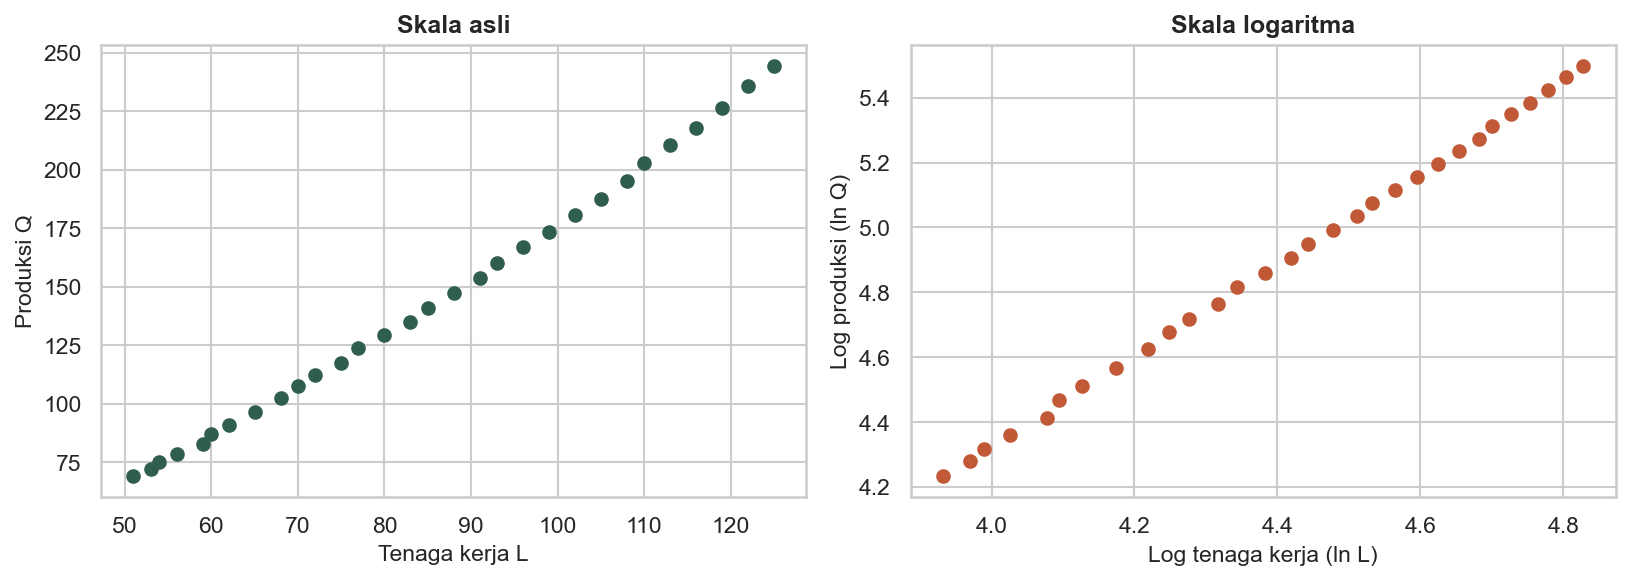

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(produksi["L"], produksi["Q"], color="#2F5D50")
axes[0].set(xlabel="Tenaga kerja L", ylabel="Produksi Q", title="Skala asli")
axes[1].scatter(produksi["lnL"], produksi["lnQ"], color="#C15937")
axes[1].set(xlabel="Log tenaga kerja (ln L)", ylabel="Log produksi (ln Q)", title="Skala logaritma")
plt.tight_layout()
plt.show()

**Cara membaca:** Bandingkan bentuk dan sebaran titik, bukan besar angka sumbu. Modal belum ditahan konstan pada gambar; interpretasi elastisitas mengikuti model yang memasukkan ln L dan ln K bersama.

In [6]:
model = LinearRegression()
model.fit(X_model, y_model)

koefisien_model = pd.Series(model.coef_, index=X_model.columns)
koefisien_model.loc["Intercept"] = model.intercept_


### Lihat hasil model: Log produksi (ln Q)

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

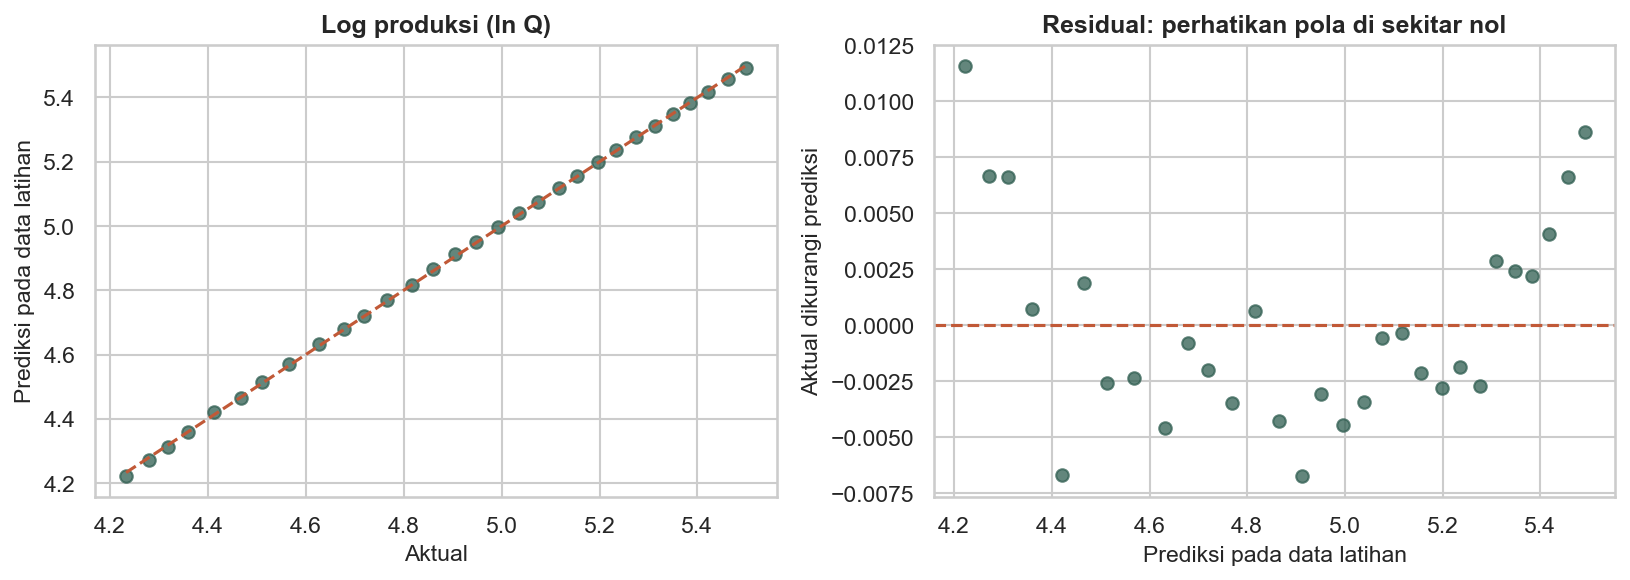

In [7]:
prediksi_visual = model.predict(X_model)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model.min(), y_model.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Log produksi (ln Q)")
axes[1].scatter(prediksi_visual, y_model - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya.

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [8]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model = sm.OLS(
    y_model,
    sm.add_constant(X_model, has_constant="add").rename(columns={"const": "Intercept"}),
).fit()
print(uji_model.summary())


                            OLS Regression Results                            
Dep. Variable:                    lnQ   R-squared:                       1.000
Model:                            OLS   Adj. R-squared:                  1.000
Method:                 Least Squares   F-statistic:                 9.819e+04
Date:                Sat, 24 Oct 2026   Prob (F-statistic):           7.35e-53
Time:                        20:23:11   Log-Likelihood:                 119.60
No. Observations:                  30   AIC:                            -233.2
Df Residuals:                      27   BIC:                            -229.0
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.9921      0.110    -18.034      0.0

### Membaca hasil

- Elastisitas tenaga kerja sekitar 0,86: tambahan tenaga kerja 1 persen
  menaikkan produksi sekitar 0,86 persen.
- Elastisitas modal sekitar 0,61.
- Jumlahnya 1,47 (lebih besar dari 1): skala pengembalian meningkat
  (increasing returns to scale).



In [9]:
b = koefisien_model
print(f"Elastisitas tenaga kerja : {b['lnL']:.3f}")
print(f"Elastisitas modal        : {b['lnK']:.3f}")
print(f"Jumlah (skala)           : {b['lnL'] + b['lnK']:.3f}")


Elastisitas tenaga kerja : 0.864
Elastisitas modal        : 0.609
Jumlah (skala)           : 1.473


### Coba sendiri (5 menit)

Pakai model Cobb-Douglas di atas. Hitung prediksi produksi untuk
L = 60 dan K = 120 (ingat: hasilnya dalam bentuk log, perlu di-exp).

Tulis di sel di bawah, baru buka jawabannya.



In [10]:
# Tulis kode Anda di sini


<details><summary>Lihat jawaban</summary>

ln Q = -1,99 + 0,86 x ln(60) + 0,61 x ln(120) = 4,46, jadi
Q = exp(4,46) sekitar 86,5.

</details>



## 2. Latihan mandiri

**Latihan 1: pendidikan dan pendapatan.** Data
`data/pendidikan_pendapatan.csv` berisi 30 responden.

Dugaan di soal: setiap tambahan tahun pendidikan menaikkan pendapatan
dalam persen, bukan nominal tetap. Model yang cocok: log-lin.

`ln(Pendapatan) ~ Tahun_Pendidikan`

Pertanyaan: berapa persen kenaikan pendapatan per satu tahun tambahan
pendidikan? (Petunjuk: koefisien dikali 100.)



<!-- kamus_variabel:pendidikan_pendapatan.csv -->

### Kenali data: Pendidikan dan pendapatan

**Data:** `data/pendidikan_pendapatan.csv`. **Satu baris:** satu responden.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Tahun_Pendidikan` | Total lama pendidikan yang telah ditempuh. | Tahun | X: penjelas |
| `Pendapatan_Tahunan` | Pendapatan yang diterima selama satu tahun. | Juta rupiah per tahun | Y: target |

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada CSV awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `ln_pendapatan` | Logaritma alami dari Pendapatan_Tahunan. | Skala logaritma |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [11]:
# didik = pd.read_csv(URL_DATA + "pendidikan_pendapatan.csv")
# didik["ln_pendapatan"] = np.log(didik["Pendapatan_Tahunan"])
# sampel_model_didik = didik[["ln_pendapatan", "Tahun_Pendidikan"]].dropna()
# X_model_didik = sampel_model_didik[["Tahun_Pendidikan"]]
# y_model_didik = sampel_model_didik["ln_pendapatan"]
#
# model_didik = LinearRegression()
# model_didik.fit(X_model_didik, y_model_didik)
#
# # Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
# uji_model_didik = sm.OLS(
#     y_model_didik,
#     sm.add_constant(X_model_didik, has_constant="add").rename(
#         columns={"const": "Intercept"}
#     ),
# ).fit()
# print(uji_model_didik.summary())


**Latihan 2: usia dan kinerja penjualan.** Data `data/usia_unit.csv`.
Hipotesisnya: kinerja naik seiring usia, memuncak, lalu menurun. Pakai
model kuadratik, lalu hitung usia puncaknya dengan rumus
$-b_1 / (2 b_2)$.

Pertanyaan: pada usia berapa kinerja mencapai puncak?



<!-- kamus_variabel:usia_unit.csv -->

### Kenali data: Usia dan kinerja penjual

**Data:** `data/usia_unit.csv`. **Satu baris:** satu tenaga penjual.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Usia` | Umur tenaga penjual. | Tahun | X: penjelas |
| `Unit_Terjual` | Jumlah penjualan bulanan pada contoh kinerja penjual. | Unit per bulan, berupa angka simulasi | Y: target |

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada CSV awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `usia2` | Kuadrat usia: usia × usia. | Tahun kuadrat |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [12]:
# usia = pd.read_csv(URL_DATA + "usia_unit.csv")
# usia["usia2"] = usia["Usia"] ** 2
# sampel_model_usia = usia[["Unit_Terjual", "Usia", "usia2"]].dropna()
# X_model_usia = sampel_model_usia[["Usia", "usia2"]]
# y_model_usia = sampel_model_usia["Unit_Terjual"]
#
# model_usia = LinearRegression()
# model_usia.fit(X_model_usia, y_model_usia)
#
# # Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
# uji_model_usia = sm.OLS(
#     y_model_usia,
#     sm.add_constant(X_model_usia, has_constant="add").rename(
#         columns={"const": "Intercept"}
#     ),
# ).fit()
# print(uji_model_usia.summary())


**Latihan 3: jam belajar dan skor ujian.** Data `data/jam_skor.csv`.
Ada efek jenuh: tambahan jam belajar makin kecil manfaatnya, dan ada
batas skor maksimal. Model yang cocok: reciprocal,
`Skor_Ujian ~ 1/X` dengan X = Jam_Belajar.

Pertanyaan: berapa batas skor maksimal (asimtot) yang dibaca dari
intersep? (Petunjuk: intersep adalah batas atas skor.)



<!-- kamus_variabel:jam_skor.csv -->

### Kenali data: Jam belajar dan hasil ujian

**Data:** `data/jam_skor.csv`. **Satu baris:** satu siswa/responden.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Jam_Belajar` | Total waktu belajar yang dicatat pada contoh. | Jam | X: penjelas |
| `Skor_Ujian` | Nilai/skor hasil ujian. | Poin skor; batas maksimum akan ditaksir dalam latihan | Y: target |

Kolom turunan berikut dibuat saat praktik; kolom ini belum ada pada CSV awal.

| Kolom turunan | Pengertian | Satuan/kode |
|---|---|---|
| `satu_per_jam` | Kebalikan jam belajar: 1 / Jam_Belajar. | Per jam |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [13]:
# skor = pd.read_csv(URL_DATA + "jam_skor.csv")
# skor["satu_per_jam"] = 1 / skor["Jam_Belajar"]
# sampel_model_skor = skor[["Skor_Ujian", "satu_per_jam"]].dropna()
# X_model_skor = sampel_model_skor[["satu_per_jam"]]
# y_model_skor = sampel_model_skor["Skor_Ujian"]
#
# model_skor = LinearRegression()
# model_skor.fit(X_model_skor, y_model_skor)
#
# # Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
# uji_model_skor = sm.OLS(
#     y_model_skor,
#     sm.add_constant(X_model_skor, has_constant="add").rename(
#         columns={"const": "Intercept"}
#     ),
# ).fit()
# print(uji_model_skor.summary())


**Latihan 4: pilih bentuk untuk data UTS.** Data `data/uts_1.csv`:
pertumbuhan ekonomi, investasi, inflasi, dan keterbukaan perdagangan.
Coba tiga bentuk: linear, log-log, dan kuadratik untuk investasi.
Bandingkan R kuadrat terkoreksi dan p-value. Kriteria: pilih model
dengan R kuadrat terkoreksi tertinggi di antara model yang tanda
koefisiennya sesuai teori. Kalau dua model berdekatan, dahulukan yang
lebih sederhana dan lebih mudah dijelaskan.



<!-- kamus_variabel:uts_1.csv -->

### Kenali data: Pertumbuhan ekonomi

**Data:** `data/uts_1.csv`. **Satu baris:** satu negara pada contoh 50 negara berkembang.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Y_Pertumbuhan_Ekonomi` | Laju pertumbuhan kegiatan ekonomi/PDB. | Persen | Y: target |
| `X1_Investasi` | Besarnya investasi dibandingkan PDB. | Persen dari PDB | X: penjelas |
| `X2_Inflasi` | Laju kenaikan tingkat harga. | Persen | X: penjelas |
| `X3_Keterbukaan_Perdagangan` | Ukuran keterbukaan perdagangan relatif terhadap PDB. | Persen dari PDB | X: penjelas |

Rumus rinci ukuran keterbukaan tidak dicantumkan pada tabel sumber; jangan menganggapnya nilai ekspor saja.

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [14]:
# uts1 = pd.read_csv(URL_DATA + "uts_1.csv")
# sampel_model_lin = uts1[
#     [
#         "Y_Pertumbuhan_Ekonomi",
#         "X1_Investasi",
#         "X2_Inflasi",
#         "X3_Keterbukaan_Perdagangan",
#     ]
# ].dropna()
# X_model_lin = sampel_model_lin[
#     ["X1_Investasi", "X2_Inflasi", "X3_Keterbukaan_Perdagangan"]
# ]
# y_model_lin = sampel_model_lin["Y_Pertumbuhan_Ekonomi"]
#
# model_lin = LinearRegression()
# model_lin.fit(X_model_lin, y_model_lin)
# ...


### Selanjutnya

Selanjutnya: Lab 3, uji asumsi klasik.
